In [ ]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()


In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

titanic_path = kagglehub.competition_download('titanic')

print('Data source import complete.')


In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/titanic/train.csv
/kaggle/input/competitions/titanic/test.csv
/kaggle/input/competitions/titanic/gender_submission.csv


In [ ]:
train_df = pd.read_csv("/kaggle/input/competitions/titanic/train.csv")
test_df = pd.read_csv("/kaggle/input/competitions/titanic/test.csv")


In [ ]:
# total population
df = pd.concat([train_df.drop(columns=['Survived']),test_df]).sample(1309)

<Axes: ylabel='Density'>

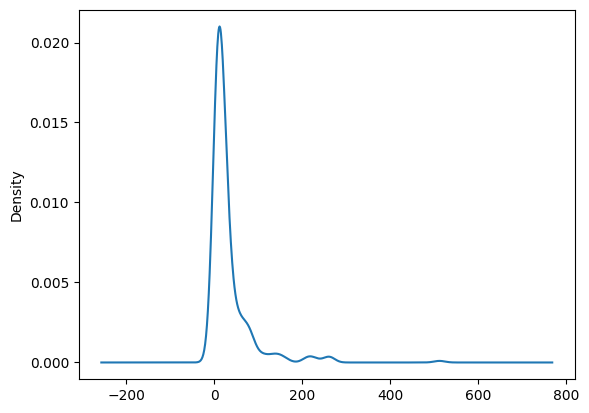

In [ ]:
df['Fare'].plot(kind='kde')

In [ ]:
# sample size = 50, 100 times

samples = []
for _ in range(100):
    samples.append(df['Fare'].dropna().sample(50).values.tolist())
samples = np.array(samples)
print(samples.shape,end="\n\n")

sampling_means = samples.mean(axis=1)

(100, 50)



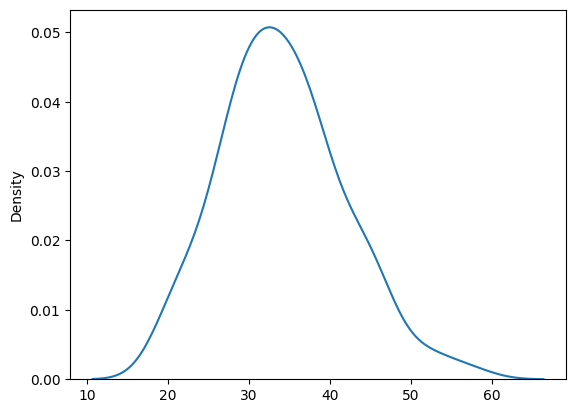

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.kdeplot(sampling_means)
plt.show(

)

In [ ]:
mean = sampling_means.mean()
std = sampling_means.std()

lower_limit = mean - 2 * std
upper_limit = mean + 2 * std

print(f"The range is {lower_limit:.2f}-{upper_limit:.2f}")

print(f"95% our population mean is within range {lower_limit:.2f}-{upper_limit:.2f}")

The range is 19.01-49.28
95% our population mean is within range 19.01-49.28


- Now, we're going to find the population mean

In [ ]:
print(f"Population mean: {df['Fare'].dropna().mean()}")
print(f"Population var: {df['Fare'].dropna().var()}")
print(f"Population std: {df['Fare'].dropna().std()}")

Population mean: 33.29547928134557
Population var: 2678.9597378928897
Population std: 51.7586682391741


In [ ]:
print(f"{sampling_means.var()}") # sigma^2/n
print(f"{sampling_means.var()*50}") # population variance
print(f"{sampling_means.std()}")

57.24820233050371
2862.4101165251855
7.5662541809341635
